In [ ]:
%pip install ucimlrepo
%pip install matplotlib

In [ ]:
# https://archive.ics.uci.edu/dataset/29/computer+hardware
from ucimlrepo import fetch_ucirepo

computer_hardware = fetch_ucirepo(id=29)
X = computer_hardware.data.features

In [ ]:
import torch
from torch import nn

In [ ]:
from torch.nn.modules.linear import Linear
class PerformanceModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear_model = nn.Sequential(
        nn.Linear(6, 8),
        nn.ReLU(),
        nn.Linear(8,4),
        nn.ReLU(),
        nn.Linear(4, 1)
    )

  def forward(self, x):
    return self.linear_model(x)

In [ ]:
features = torch.tensor(X[["MYCT", "MMIN", "MMAX", "CACH", "CHMIN", "CHMAX"]].values, dtype=torch.float)
target = torch.tensor(X["PRP"].values, dtype=torch.float).unsqueeze(1)

In [ ]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

train_data, test_data = random_split(TensorDataset(features, target), [0.8, 0.2])
train_loader = DataLoader(train_data, 10, shuffle=True)
test_loader = DataLoader(test_data, 10, shuffle=True)

In [ ]:
from torch.optim import optimizer
import torch.optim as optim

model = PerformanceModel()

loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters())
epochs = 1500

for epoch in range(epochs):
  model.train()
  for data in train_loader:
    inputs, labels = data
    optimizer.zero_grad()
    outputs = model(inputs)

    loss = loss_fn(outputs, labels)
    loss.backward()

    optimizer.step()

In [ ]:
all_errors = []
all_predictions = []
all_expected = []
model.eval()

with torch.no_grad():
  for data in test_loader:
    inputs, expected = data
    outputs = model(inputs)
    all_predictions.append(outputs)
    all_expected.append(expected)
    diff = outputs - expected
    all_errors.append(diff)

# Unimos todos los tensores de los lotes en uno solo
all_errors = torch.cat(all_errors)

# Ahora puedes calcular métricas sobre todos los datos juntos
mae = torch.mean(torch.abs(all_errors)) # Error Absoluto Medio (MAE)
mse = torch.mean(all_errors ** 2)       # MSE

print(f"MAE: {mae.item():.4f}")
print(f"MSE: {mse.item():.4f}")


MAE: 40.4666
MSE: 2951.0684


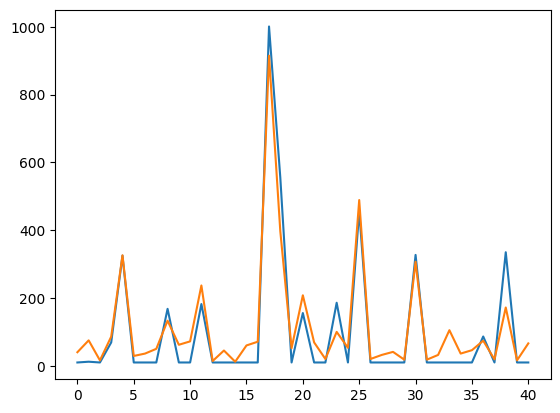

In [ ]:
import matplotlib.pyplot as plt

all_predictions = torch.cat(all_predictions).numpy()
all_expected = torch.cat(all_expected).numpy()

plt.plot(all_predictions)
plt.plot(all_expected)
plt.show()

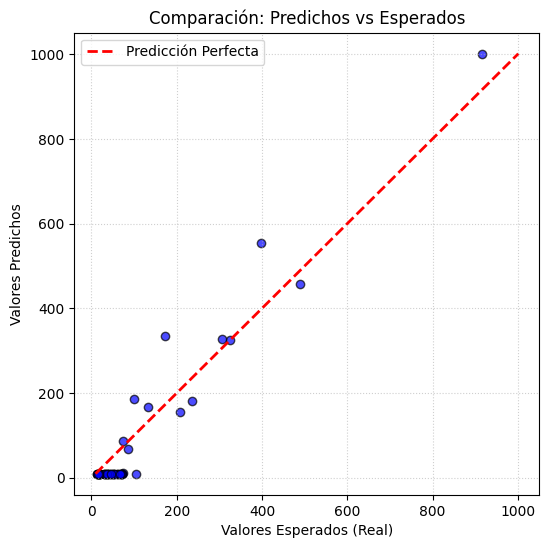

In [ ]:
import numpy as np

# Asegurarnos de que sean arreglos 1D
y_true = all_expected.squeeze()
y_pred = all_predictions.squeeze()

plt.figure(figsize=(6, 6))
plt.scatter(y_true, y_pred, alpha=0.7, color='blue', edgecolors='k')

# Dibujar la línea ideal (y = x) para referencia
min_val = min(np.min(y_true), np.min(y_pred))
max_val = max(np.max(y_true), np.max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta')

plt.xlabel('Valores Esperados (Real)')
plt.ylabel('Valores Predichos')
plt.title('Comparación: Predichos vs Esperados')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()